# ЛР 3: анализ ответов YandexGPT Pro 5.1

Ноутбук читает сохранённые ответы; запросов к API и запуска кода из ответов при Run All нет. Все исходные ответы неизменны. Пять отладочных задач исключены из оценки. Восемь программ D ранее выполнены отдельно без исправлений после просмотра исходников; их stdout/stderr и hashes сохранены.

Численные таблицы и статусы гипотез получаются программно. Итоговые выводы отчёта и разбор ошибок команда формулирует самостоятельно. H5 ожидает Qwen; C/D требуют двух независимых проверяющих. Значения отсутствующих оценок не заменяются нулями.

In [1]:
from pathlib import Path
import sys, json, csv, html
from IPython.display import display, HTML, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'yandex_runner.py').exists() and (p/'results/models/yandex/yandex-v1/events.jsonl').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from analyze_yandex import analyze
if not (ROOT/'analysis/yandex/preliminary_review.csv').exists():
    from create_preliminary_review import create
    create(ROOT)
summary=analyze(ROOT)
OUT=ROOT/'analysis/yandex'
def show_json(name):
    print(json.dumps(json.loads((OUT/name).read_text(encoding='utf-8')),ensure_ascii=False,indent=2))
def show_csv(name):
    with (OUT/name).open(encoding='utf-8-sig',newline='') as f:
        rows=list(csv.DictReader(f))
    keys=list(rows[0])
    content='<table><tr>'+''.join('<th>'+html.escape(k)+'</th>' for k in keys)+'</tr>'
    content+=''.join('<tr>'+''.join('<td>'+html.escape(str(r[k]))+'</td>' for k in keys)+'</tr>' for r in rows)
    display(HTML(content+'</table>'))
def figure(name): display(Image(filename=str(OUT/'figures'/name)))
def show_model_answers(prefix):
    tasks={r['id']:r for r in [json.loads(s) for s in (ROOT/'data/tasks.jsonl').read_text(encoding='utf-8').splitlines()]}
    records=[json.loads(s) for s in (ROOT/'results/models/yandex/yandex-v1/responses.jsonl').read_text(encoding='utf-8').splitlines()]
    executions={r['task_id']:r for r in json.loads((OUT/'code_execution.json').read_text(encoding='utf-8'))}
    def pre(value):
        if not isinstance(value,str): value=json.dumps(value,ensure_ascii=False,indent=2)
        return '<pre style="white-space:pre-wrap">'+html.escape(value)+'</pre>'
    for row in sorted([r for r in records if r['stage']=='main' and r['task_id'].startswith(prefix)],key=lambda r:r['task_id']):
        task=tasks[row['task_id']]
        raw='\n'.join(p.get('text','') for i in row['raw_response'].get('output',[]) for p in i.get('content',[]) if p.get('type')=='output_text')
        obj=row.get('parsed')
        if obj is None:
            # Display valid JSON content even if its answer type failed the scoring schema.
            # This never changes stored results or scores (e.g. C07's list-valued answer).
            lines=raw.strip().splitlines(); fence=chr(96)*3
            body='\n'.join(lines[1:-1]) if len(lines)>=3 and lines[0].strip() in (fence,fence+'json') and lines[-1].strip()==fence else raw
            try: obj=json.loads(body)
            except ValueError: obj={}
        content='<h3>'+html.escape(row['task_id'])+'</h3><b>Условие</b>'+pre(task['text_ru'])
        content+='<b>Ответ Яндекса (без исправлений)</b>'+pre(obj.get('answer',raw))
        content+='<b>Обоснование модели</b>'+pre(obj.get('explanation',''))
        content+='<p>Уверенность: '+html.escape(str(obj.get('confidence','не извлечена')))+'; отметка формата: '+html.escape(str(row.get('error')))+'.</p>'
        if prefix=='D':
            outcome=executions[row['task_id']]
            content+='<b>Результат запуска</b>'+pre({k:outcome[k] for k in ['exit_code','pass_at_1','output_is_json','metrics_match_reference']})
            for name in ['stdout','stderr']:
                p=OUT/'code_execution'/(row['task_id']+'.'+name+'.txt')
                content+='<b>'+name+'</b>'+pre(p.read_text(encoding='utf-8'))
        content+='<details><summary>Эталон и критерии проверки</summary>'+pre({'reference':task['reference'],'rubric':task['rubric']})+'</details>'
        content+='<p><b>Ручная оценка: ожидаются два независимых проверяющих.</b></p>'
        display(HTML(content))
print('Analysis API calls:',summary['api_calls_during_analysis'])

Analysis API calls: 0


## Комплектность и расходы

344 уникальных полученных ответа: pilot=5, main=39, zero/five/twenty по 100. Две оборванные попытки разрешены пользователем к повтору, но не считаются дополнительными ответами. Известная стоимость вычисляется по usage. В бюджетном журнале дополнительно оставлены резервы неизвестных попыток; они не являются подтверждённым списанием. Фактический платёж сверяется с Billing.

In [2]:
show_json('summary.json')
show_csv('costs.csv')

{
  "responses": 344,
  "unique_requests": 344,
  "counts": {
    "pilot": 5,
    "main": 39,
    "zero": 100,
    "five": 100,
    "twenty": 100
  },
  "known_cost_rub": 248.4592,
  "budget_ledger_rub": 266.4575999999999,
  "unknown_attempt_reserve_rub": 17.99839999999989,
  "tokens": 310574,
  "main_and_E_cost_rub": 247.15120000000002,
  "auto_ABF": {
    "accuracy": 0.5416666666666666,
    "ci_low": 0.3333333333333333,
    "ci_high": 0.75
  },
  "auto_ABF_n": 24,
  "code_pass_at_1": 0.75,
  "code_json_output_rate": 0.625,
  "format_errors": {
    "markdown_wrapper": 236,
    "invalid_answer_type": 101,
    "invalid_json": 2
  },
  "refusals_E_zero": 100,
  "review_items": 23,
  "overall_39_accuracy": null,
  "reason": "C and D require two independent reviews; B explanation scores also pending",
  "bootstrap_iterations": 1000,
  "seed": 42,
  "api_calls_during_analysis": 0,
  "hypotheses_status": {
    "H5": "pending_other_model",
    "H10": "confirm",
    "H12": "insufficient_data"


stage,n,cost_rub,mean_latency_s
pilot,5,1.308,19.414793039998038
main,39,14.8536,20.178097635897874
zero,100,28.8936,19.321040879999636
five,100,59.5016,23.608642006999872
twenty,100,143.9024,17.619396366998846


## Автоматическая оценка A, B, F

Числа проверяются с допуском банка, B — по вердикту; обоснования B оцениваются отдельно вручную. Неразбираемые ответы считаются неуспехами, а не удаляются из знаменателя. Единственная внешняя Markdown-оболочка снимается по правилу, зарегистрированному до основных запросов; нарушение чистого JSON фиксируется отдельно. Недопустимые JSON-дроби вроде `2/3` не вычисляются и не исправляются.

Сводная оценка здесь относится к 24 задачам A+B+F. Итоговой accuracy по 39 задачам пока нет: C и D ещё не получили две независимые оценки. Для 8/8 верных ответов B обычный непараметрический bootstrap даёт вырожденный интервал [1,1]; это ограничение метода на малой выборке, а не гарантия отсутствия ошибок на новых задачах.

type,n,accuracy,ci_low,ci_high
A,8,0.125,0.0,0.375
B,8,1.0,1.0,1.0
F,8,0.5,0.125,0.875


task_id,type,parsed,answer,correct,confidence,format_error,cost_rub
A01,A,True,0.32,False,100,markdown_wrapper,0.3952
A02,A,True,0.1388888888888889,False,100,markdown_wrapper,0.4464
A03,A,True,0.6363636363636364,False,100,markdown_wrapper,0.3728
A04,A,True,1.25,False,100,markdown_wrapper,0.28800000000000003
A05,A,True,0.598704919,False,100,markdown_wrapper,0.32080000000000003
A06,A,True,0,False,100,markdown_wrapper,0.33840000000000003
A07,A,True,0.2,True,100,markdown_wrapper,0.28800000000000003
A08,A,True,0.7,False,90,markdown_wrapper,0.3672
B01,B,True,False,True,100,markdown_wrapper,0.2432
B02,B,True,False,True,95,markdown_wrapper,0.2528


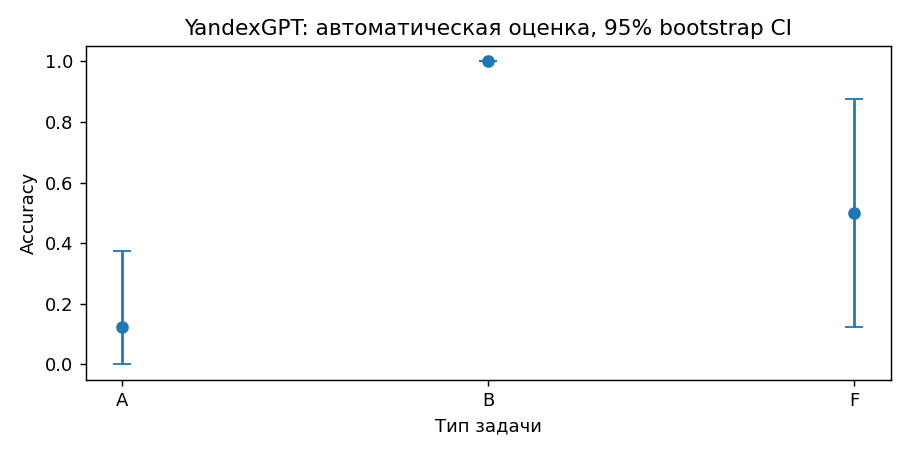

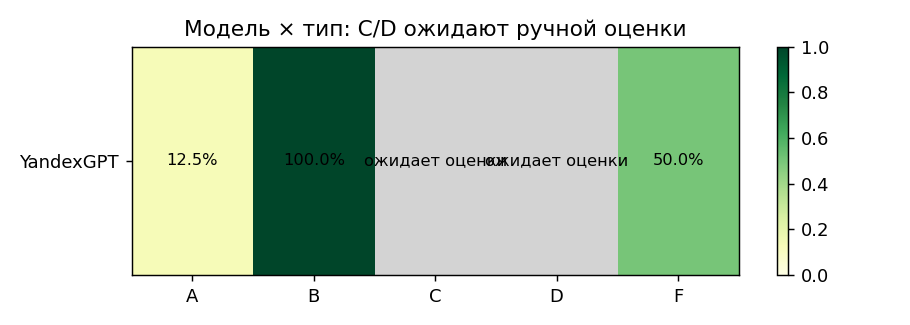

In [3]:
show_csv('type_metrics.csv')
show_csv('automatic_scores.csv')
figure('accuracy_ci.png')
figure('heatmap.png')

## Тип E: классификация

Одни и те же 100 строк и шесть признаков; train5 является подмножеством train20. Положительный редкий класс здесь 1=malignant (в D08 сохранена исходная sklearn-кодировка). У LLM в zero-shot все ответы — `insufficient_data`: это отказы, не предсказания класса 0. При расчёте эффективного качества отказ считается ошибкой для его истинного класса; coverage=0. Метрики на подмножестве ответов в этом режиме не определены, поскольку такого подмножества нет. F1/BA с отказами показаны как эффективные нулевые оценки. Для классических моделей zero-shot не определён.

Интервалы условны на фиксированные train5/train20; они не включают разброс выбора демонстрационных примеров.

model,shots,f1_minority,balanced_accuracy,accuracy,coverage,abstentions
YandexGPT,0,0.0,0.0,0.0,0.0,100
YandexGPT,5,0.7708333333333334,0.8253968253968254,0.78,1.0,0
YandexGPT,20,0.9014084507042254,0.9165594165594166,0.93,1.0,0
LogisticRegression,5,0.8043478260869565,0.8571428571428572,0.82,1.0,0
LogisticRegression,20,0.9117647058823529,0.9189189189189189,0.94,1.0,0
GaussianNB,5,0.8043478260869565,0.8571428571428572,0.82,1.0,0
GaussianNB,20,0.8181818181818182,0.848991848991849,0.88,1.0,0
constant_majority,0,0.0,0.5,0.63,1.0,0


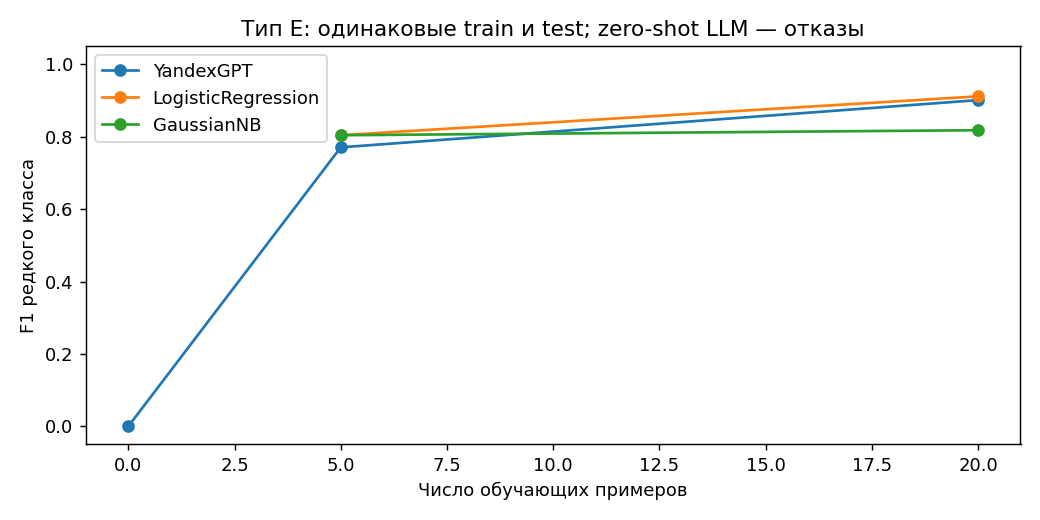

[
  {
    "model": "YandexGPT",
    "shots": 0,
    "f1_minority": 0.0,
    "balanced_accuracy": 0.0,
    "accuracy": 0.0,
    "coverage": 0.0,
    "abstentions": 100,
    "ci": {
      "f1_minority": [
        0.0,
        0.0
      ],
      "balanced_accuracy": [
        0.0,
        0.0
      ],
      "accuracy": [
        0.0,
        0.0
      ]
    }
  },
  {
    "model": "YandexGPT",
    "shots": 5,
    "f1_minority": 0.7708333333333334,
    "balanced_accuracy": 0.8253968253968254,
    "accuracy": 0.78,
    "coverage": 1.0,
    "abstentions": 0,
    "ci": {
      "f1_minority": [
        0.6666666666666666,
        0.8571428571428571
      ],
      "balanced_accuracy": [
        0.765625,
        0.8846153846153846
      ],
      "accuracy": [
        0.7,
        0.86
      ]
    }
  },
  {
    "model": "YandexGPT",
    "shots": 20,
    "f1_minority": 0.9014084507042254,
    "balanced_accuracy": 0.9165594165594166,
    "accuracy": 0.93,
    "coverage": 1.0,
    "abstentions": 0

In [4]:
show_csv('classification_metrics.csv')
figure('classification_f1.png')
show_json('classification_metrics.json')

## H10: калибровка уверенности

Предварительно выбраны A+B+F. Уверенность и точность сравниваются только для разбираемых ответов с валидной confidence; coverage и accuracy по полному знаменателю показаны явно. В B измеряется вердикт, а не качество объяснения. ECE имеет пять равных bins; confidence=1 включается в последний. Направление завышения определяется signed gap, а не самой величиной ECE. Bootstrap сохраняет пары F как кластеры.

{
  "n_total": 24,
  "n_valid": 22,
  "coverage": 0.9166666666666666,
  "mean_confidence": 0.9931818181818183,
  "accuracy_on_valid": 0.5909090909090909,
  "full_denominator_accuracy": 0.5416666666666666,
  "gap": 0.4022727272727273,
  "ci_low": 0.18745535714285713,
  "ci_high": 0.625,
  "ece": 0.40227272727272734,
  "decision": "confirm",
  "bins": [
    {
      "bin_low": 0.0,
      "bin_high": 0.2,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.2,
      "bin_high": 0.4,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.4,
      "bin_high": 0.6,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.6,
      "bin_high": 0.8,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.8,
      "bin_high": 1.0,
      "n": 22,
      "mean_confidence": 0.9931818181818183,
      "accuracy": 0.59090909090

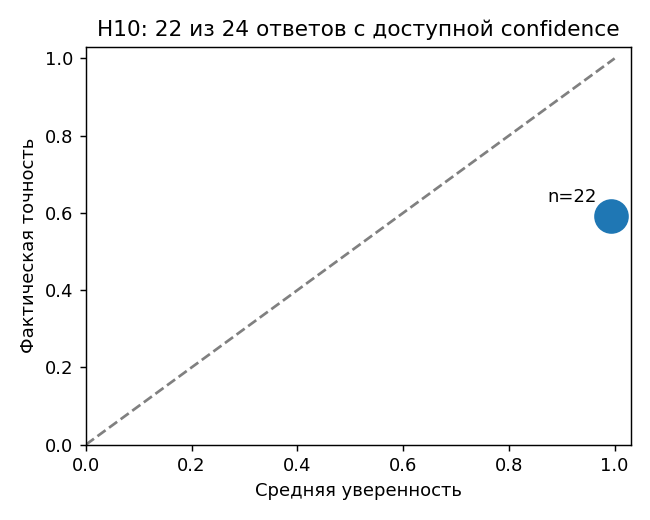

In [5]:
hypotheses=json.loads((OUT/'hypotheses.json').read_text(encoding='utf-8'))
print(json.dumps(hypotheses['H10'],ensure_ascii=False,indent=2))
figure('reliability.png')

## H12: LLM и логистическая регрессия

Первичная метрика F1 редкого класса. Заранее выбран допуск не меньшего качества 0.05; delta=F1_LLM−F1_LR. При 5 примерах нижняя односторонняя 95% граница должна превышать −0.05, при 20 верхняя должна быть ниже 0. Парный bootstrap: одни и те же тестовые индексы для моделей, 1000 повторов, seed=42. Эти односторонние границы отличаются от двухсторонних 95% CI для отдельных метрик. Недостаточная доказательность не означает равенство моделей. Результаты классических baseline были известны до регистрации; результаты LLM — нет.

{
  "decision": "insufficient_data",
  "comparisons": [
    {
      "shots": 5,
      "delta_f1_llm_minus_lr": -0.03351449275362317,
      "one_sided_95_lower": -0.07400379506641375,
      "one_sided_95_upper": 0.00035392535392503316,
      "decision": "insufficient_data"
    },
    {
      "shots": 20,
      "delta_f1_llm_minus_lr": -0.01035625517812755,
      "one_sided_95_lower": -0.07047606908418841,
      "one_sided_95_upper": 0.057967356396802235,
      "decision": "insufficient_data"
    }
  ]
}


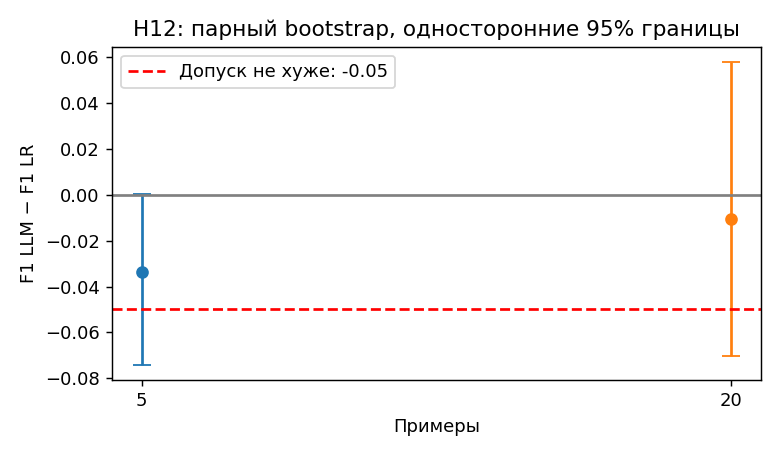

In [6]:
print(json.dumps(hypotheses['H12'],ensure_ascii=False,indent=2))
figure('h12_delta.png')

## H5 и сравнение четырёх моделей

Показатели Яндекса на A и B готовы, но проверка H5 требует совпадающих ответов Qwen3 4B. В её отсутствие статус `pending_other_model`. Тест Макнемара между моделями и итоговый сравнительный график не рассчитываются с вымышленными данными. При получении остальных моделей использовать exact McNemar для парной правильности и заранее выбранную поправку Holm для семейства сравнений.

{
  "decision": "pending_other_model",
  "needed": "Qwen3 4B answers to A/B",
  "yandex_A": 0.125,
  "yandex_B": 1.0
}


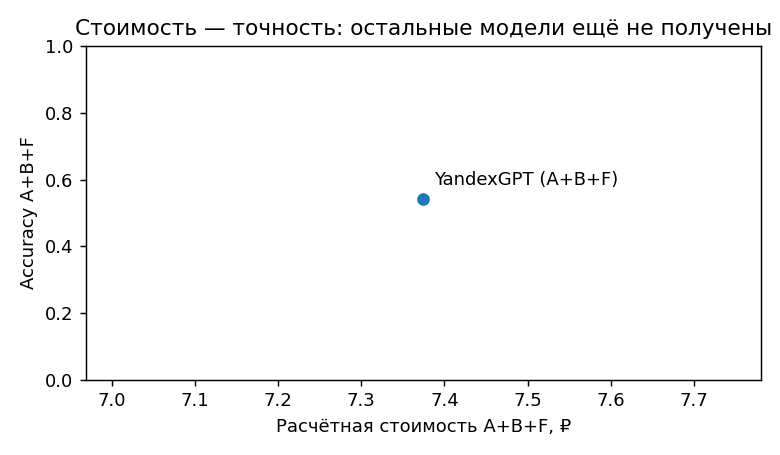

In [7]:
print(json.dumps(hypotheses['H5'],ensure_ascii=False,indent=2))
figure('cost_accuracy.png')

## C: все ответы на выбор метода

Ниже приведены все семь исходных ответов C01-C07 с условиями, обоснованиями и уверенностью модели. Ответы получены и сохранены; отсутствуют только два независимых балла по рубрике. C07 показывает исходный список методов и нарушение типа JSON-поля; отображение содержимого не меняет результаты автоматического парсинга.

In [8]:
show_model_answers('C')

## D: запуск исходного кода

Это техническая проверка запуска, не замена двух независимых проверок методологии. В каждом файле сохранена исходная строка answer без исправлений. Проверялись зафиксированные версии sklearn/numpy. Отдельно показаны запуск, формат stdout и совпадение метрик; диагностическое извлечение числа из Python dict не превращает этот вывод в JSON. Алиасы test_accuracy→accuracy и silhouette_score→silhouette применены только при сопоставлении названий метрик.

Повторный Run All этого ноутбука лишь читает результаты уже выполненных программ; новые исполнения неизвестного кода не производятся.

task_id,source_sha256,exit_code,pass_at_1,output_is_json,metrics_match_reference,methodology_review,stderr_original_sha256,traceback_paths_normalized
D01,9b5ac5c9f0a8fd29dc77f70ae4dd6a10993ecab56f52d99662a2391eb4163371,0,True,False,True,pending_two_independent_reviewers,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True
D02,f737f8e088d63ecbd4e72d9d5325e71a1efa153b77475ec384af22f65ab4bd78,1,False,False,False,pending_two_independent_reviewers,243d0324395ba28ba8a126b7decdf0c1877e50eb6adfabe1a22543113294b749,True
D03,8725e9967da7fff9571802732e7e9a9f9bbec9005a3720746e3606e0c7cbba05,0,True,True,True,pending_two_independent_reviewers,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True
D04,3846b87c22bf9cc9cc8883474f91f630647e1f59804a2789a9759be80e25e100,0,True,True,True,pending_two_independent_reviewers,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True
D05,baefddd7238927635eae4d0453e9e5ec44e5f052b1adb9d5cdfb481a980f4378,0,True,True,True,pending_two_independent_reviewers,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True
D06,4b858bf9558a551f1329bd4433dc7790d20d4508e9847f04edd65247057b2110,1,False,False,False,pending_two_independent_reviewers,e3f4d29268bb2e08685a4aafc6a52019f75e985850afab1c37ee75e510adb0e1,True
D07,c8c83165382d11bf4a650bd87364cc5e426b411e40a691b16b88ac6ce05bceb1,0,True,True,True,pending_two_independent_reviewers,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True
D08,c68700963ef922ff3e85a9a8e52916c93e48a49c0177375d496d261c0da4e2e1,0,True,True,True,pending_two_independent_reviewers,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True


[
  {
    "task_id": "D01",
    "source_sha256": "9b5ac5c9f0a8fd29dc77f70ae4dd6a10993ecab56f52d99662a2391eb4163371",
    "exit_code": 0,
    "pass_at_1": true,
    "output_is_json": false,
    "metrics": {
      "best_C": 10,
      "balanced_accuracy": 0.9794549266247379
    },
    "metrics_match_reference": true,
    "stderr": "",
    "methodology_review": "pending_two_independent_reviewers",
    "stderr_original_sha256": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "traceback_paths_normalized": true
  },
  {
    "task_id": "D02",
    "source_sha256": "f737f8e088d63ecbd4e72d9d5325e71a1efa153b77475ec384af22f65ab4bd78",
    "exit_code": 1,
    "pass_at_1": false,
    "output_is_json": false,
    "metrics": null,
    "metrics_match_reference": false,
    "stderr": "Traceback (most recent call last):\n  File \"<project>/D02.py\", line 35, in <module>\n    print(json.dumps({\"f1\": f1, \"balanced_accuracy\": balanced_acc}))\n          ^^^^\nNameError: name 'json'

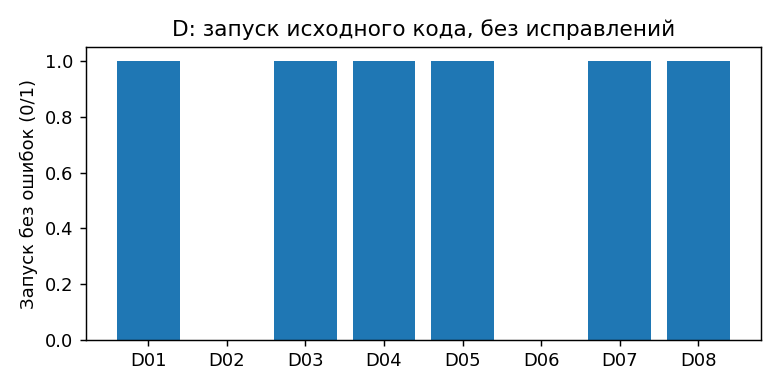

In [9]:
show_csv('code_metrics.csv')
show_json('code_execution.json')
figure('code_execution.png')

### D01-D08: полный код и фактический результат каждого запуска

Ниже сохранённый код модели, исходный stdout и stderr. Ячейка только показывает ранее полученные результаты и не исполняет этот код заново. Ошибки модели не исправлены.

In [10]:
show_model_answers('D')

## Предварительная проверка B/C/D

Ниже одна предварительная проверка по рубрикам. В B/C выставлены предварительные баллы, в D отдельно отмечены методологические признаки и фактическая запускаемость. Она не является двумя независимыми оценками участников, не заполняет их формы и не используется для расчёта Cohen kappa. Итоговые показатели ручной проверки остаются незаполненными до её фактического проведения.

In [11]:
show_csv('preliminary_review.csv')

task_id,type,score_0_2,rationale,leakage,test_tuning,train_evaluation,wrong_metric,missing_stratification,missing_seed,pass_at_1,assessment_status
B01,B,2,Вердикт верен: PCA не использует метки и максимизирует дисперсию.,,,,,,,,preliminary_single_review
B02,B,2,Вердикт верен; указана связь некалиброванности с нарушением предположения независимости.,,,,,,,,preliminary_single_review
B03,B,1,Утечка через статистики test объяснена верно. Не указан обязательный способ исправления: fit только на train и внутри CV.,,,,,,,,preliminary_single_review
B04,B,2,Различие ROC-AUC и precision при конкретном пороге объяснено; зависимость от базовой частоты указана.,,,,,,,,preliminary_single_review
B05,B,2,Правильно объяснены штраф за нарушения зазора и более слабая регуляризация при росте C.,,,,,,,,preliminary_single_review
B06,B,2,"Правильно связаны масштаб признака, расстояние и возможная смена соседей.",,,,,,,,preliminary_single_review
B07,B,1,Вердикт верен. Фраза об обучении каждого дерева на разных наборах признаков неточна для обычного RandomForest: случайное подмножество выбирается при поиске разбиений в узлах.,,,,,,,,preliminary_single_review
B08,B,2,"Верно названы целевая функция, зависимость от инициализации и возможность локального минимума.",,,,,,,,preliminary_single_review
C01,C,1,"Логистическая регрессия, масштабирование и риск p>n разумны. Не описаны настройка регуляризации, стратификация и fit preprocessing внутри CV.",,,,,,,,preliminary_single_review
C02,C,2,"Предложены KMeans, стандартизация, выбор k методом локтя и инженерная проверка центроидов; это допустимое решение по рубрике.",,,,,,,,preliminary_single_review


## Материалы двум проверяющим

`analysis/yandex/review/REVIEW.md` и `responses.json` содержат 23 ответа B/C/D с анонимными идентификаторами. Каждому проверяющему — отдельный CSV reviewer_1/reviewer_2, независимо. Ключ `review_key.json` не передавать проверяющим. Для настоящей слепой проверки нужно перемешать ответы всех моделей: пакет одной модели сам по себе не скрывает её происхождение.

Рубрики и эталоны сохранены. Пропущенные оценки остаются пропусками. При наличии пар оценок рассчитывается Cohen kappa; при κ<0.6 рубрика уточняется и ответы переоцениваются. Разногласия требуют согласования, а не автоматического усреднения.

In [12]:
show_json('review_status.json')

{
  "B": {
    "n_required": 8,
    "n_paired_scores": 0,
    "kappa": null,
    "status": "pending"
  },
  "C": {
    "n_required": 7,
    "n_paired_scores": 0,
    "kappa": null,
    "status": "pending"
  },
  "D": {
    "n_required": 8,
    "n_paired_scores": 0,
    "flag_agreement": {
      "leakage": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "test_tuning": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "train_evaluation": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "wrong_metric": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "missing_stratification": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "missing_seed": {
        "n": 0,
        "kappa": null,
        "agreement": null
      }
    },
    "status": "pending"
  }
}


## Пять кандидатов для разбора ошибок

Выбраны первые пять неверных автоматических ответов в порядке ID, без отбора по удобному выводу. Здесь исходные цитаты и эталон. Поле student_analysis оставлено пустым: разбор причин ошибки и текст отчёта заполняют участники.

In [13]:
show_json('error_examples.json')

[
  {
    "task_id": "A01",
    "prompt": "Дефект имеют 2% деталей. Датчик срабатывает на 96% дефектных и на 4% исправных деталей. Найдите вероятность дефекта при срабатывании датчика. Ответ дайте долей от 0 до 1.",
    "raw_response": "```\n{\n    \"answer\": 0.32,\n    \"explanation\": \"Используем формулу Байеса. Пусть D — событие, что деталь дефектна, S — событие, что датчик сработал. Нам нужно найти P(D|S). По формуле Байеса: P(D|S) = P(S|D) * P(D) / P(S). P(S|D) = 0.96 (вероятность срабатывания датчика при дефекте), P(D) = 0.02 (вероятность дефекта), P(S) = P(S|D) * P(D) + P(S|¬D) * P(¬D) = 0.96 * 0.02 + 0.04 * 0.98 = 0.0192 + 0.0392 = 0.0584. Тогда P(D|S) = 0.96 * 0.02 / 0.0584 ≈ 0.32.\",\n    \"confidence\": 100\n}\n```",
    "reference": {
      "answer": 0.3287671232876712,
      "solution_ru": "P(D|+) = 0.02*0.96 / (0.02*0.96 + 0.98*0.04) = 24/73."
    },
    "automatic_correct": false,
    "student_analysis": ""
  },
  {
    "task_id": "A02",
    "prompt": "В узле дерева 36

## Что осталось для окончательной сдачи

Две независимые проверки B-обоснований/C/D; согласование разногласий и при необходимости переоценка; данные Qwen для H5 и остальных моделей для общего сравнения; финальная сводная оценка; пять разборов ошибок, минимум три ограничения, рекомендации и доклад. Ограничения методики: малый банк, один фиксированный набор few-shot примеров, публичный датасет, парные задачи и пропуски confidence. Это перечень аспектов для обсуждения, а не готовые исследовательские выводы.